# Credit Worthiness Prediction

**Life cycle of the Machine Learning project**

* Understanding the problem statement
* Data collection
* Exploratory data analysis
* Data cleaning
* Data pre-processing
* Model training
* Choosing the best model

### About

A bank has to decide, for every loan application it receives, whether the applicant is likely to
pay the money back. The decision is traditionally taken by a credit officer who reads the
application form: how much money is requested, for how long, what the applicant already owns,
how stable the employment is and how the previous credits were repaid.

The `CreditWorthiness` dataset stores exactly this information for one thousand past applications,
together with the score the bank finally assigned to each of them.

## 1) Problem statement

* The bank wants to shortlist the applications automatically, so that the credit officers can
  spend their time on the borderline cases only.

**In this project we build a classification model:**

* The model tells whether the credit score of an applicant is **good** or **bad**.
* It can be used to recommend which applications should be approved, and which ones carry a high
  risk of default and deserve a manual review.

## 2) Data collection

* The dataset is stored in `data/CreditWorthiness.xlsx`, sheet `Data`.
* It consists of 1000 rows and 21 columns.

### 2.1 Import the data and the required packages

**Importing pandas, numpy, matplotlib, seaborn and the warnings library.**

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

%matplotlib inline

**Import the Excel data as a pandas DataFrame**

The workbook ships abbreviated column names (`Cbal`, `Cdur`, `Chist`, ...). The very same
mapping that the production pipeline applies lives in `config/schema.yaml`, so we reuse it here
instead of duplicating it in the notebook.

In [ ]:
schema = yaml.safe_load(open("../config/schema.yaml", "rb"))

df = pd.read_excel("../data/CreditWorthiness.xlsx", sheet_name="Data")
df = df.rename(columns=schema["raw_column_mapping"])

for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.replace(r"\s+", " ", regex=True).str.strip()

df.head()

,checking_balance,credit_duration,credit_history,credit_purpose,credit_amount,savings_balance,employment_duration,installment_rate,marital_status_gender,other_parties,residence_duration,property_type,age,installment_plans,housing_type,existing_credits,job_type,num_dependents,telephone,foreign_worker,credit_score
0,0 <= Rs. < 2000,9,all settled till now,Business,13790,Rs. < 1000,1 to 4 years,2,married or widowed male,no one,less than a year,real estate,27,bank,own,1,employee with official position,1,yes,no,good
1,0 <= Rs. < 2000,15,dues not paid earlier,electronics,15250,no savings account,more than 7 years,4,single male,"yes, guarantor",more than 3 years,real estate,50,none,own,2,employee with official position,1,yes,no,good
2,0 <= Rs. < 2000,36,none taken/all settled,Business,19410,Rs. < 1000,more than 7 years,4,single male,no one,more than 3 years,Unknown,61,none,free,1,"employed either in management, self or in high...",1,yes,no,bad
3,0 <= Rs. < 2000,48,none taken/all settled,Business,144090,Rs. < 1000,1 to 4 years,2,single male,no one,1 to 2 years,Other cars etc.,25,none,own,1,employee with official position,1,yes,no,bad
4,no checking account,24,all settled till now,electronics,31690,Rs. < 1000,less than 1 year,4,divorced or separated or married female,no one,more than 3 years,life insurance/building society,26,none,own,1,employee with official position,1,yes,no,good


**Shape of the dataset**

In [3]:
df.shape

(1000, 21)

**Summary of the dataset**

In [ ]:
df.describe()

,credit_duration,credit_amount,installment_rate,age,existing_credits,num_dependents
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,32592.58000,2.973000,35.546000,1.407000,1.155000
std,12.058814,28227.36876,1.118715,11.375469,0.577654,0.362086
min,4.000000,2380.00000,1.000000,19.000000,1.000000,1.000000
25%,12.000000,13535.00000,2.000000,27.000000,1.000000,1.000000
50%,18.000000,23075.00000,3.000000,33.000000,1.000000,1.000000
75%,24.000000,39602.50000,4.000000,42.000000,2.000000,1.000000
max,72.000000,184120.00000,4.000000,75.000000,4.000000,2.000000


**Check the datatypes in the dataset**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   checking_balance       1000 non-null   object
 1   credit_duration        1000 non-null   int64 
 2   credit_history         1000 non-null   object
 3   credit_purpose         1000 non-null   object
 4   credit_amount          1000 non-null   int64 
 5   savings_balance        1000 non-null   object
 6   employment_duration    1000 non-null   object
 7   installment_rate       1000 non-null   int64 
 8   marital_status_gender  1000 non-null   object
 9   other_parties          1000 non-null   object
 10  residence_duration     1000 non-null   object
 11  property_type          1000 non-null   object
 12  age                    1000 non-null   int64 
 13  installment_plans      1000 non-null   object
 14  housing_type           1000 non-null   object
 15  existing_credits      

**Meaning of every column**

| Column | Meaning |
| --- | --- |
| `checking_balance` | balance of the current account |
| `credit_duration` | duration of the requested credit, in months |
| `credit_history` | how the previous credits were repaid |
| `credit_purpose` | what the money is needed for |
| `credit_amount` | amount of the requested credit |
| `savings_balance` | balance of the savings account |
| `employment_duration` | how long the applicant has held the current job |
| `installment_rate` | installment as a percentage of the disposable income, 1 to 4 |
| `marital_status_gender` | marital status combined with gender |
| `other_parties` | co-applicants or guarantors |
| `residence_duration` | how long the applicant has lived at the present address |
| `property_type` | most valuable property owned |
| `age` | age of the applicant |
| `installment_plans` | other installment plans running |
| `housing_type` | owned, rented or free housing |
| `existing_credits` | number of credits already held at this bank |
| `job_type` | qualification of the applicant |
| `num_dependents` | number of people financially dependent on the applicant |
| `telephone` | whether a telephone is registered |
| `foreign_worker` | whether the applicant is a foreign worker |
| `credit_score` | **target**, good or bad |

## 3. Exploring the data

In [ ]:
numeric_features = [feature for feature in df.columns if df[feature].dtype != "O"]
categorical_features = [feature for feature in df.columns if df[feature].dtype == "O"]

print("We have {} numerical features : {}".format(len(numeric_features), numeric_features))
print("\nWe have {} categorical features : {}".format(len(categorical_features), categorical_features))

We have 6 numerical features : ['credit_duration', 'credit_amount', 'installment_rate', 'age', 'existing_credits', 'num_dependents']

We have 15 categorical features : ['checking_balance', 'credit_history', 'credit_purpose', 'savings_balance', 'employment_duration', 'marital_status_gender', 'other_parties', 'residence_duration', 'property_type', 'installment_plans', 'housing_type', 'job_type', 'telephone', 'foreign_worker', 'credit_score']


In [ ]:
for col in categorical_features:
    print(df[col].value_counts(normalize=True) * 100)
    print("---------------------------")

checking_balance
no checking account    39.4
Rs. < 0                27.4
0 <= Rs. < 2000        26.9
Rs. >=2000              6.3
Name: proportion, dtype: float64
---------------------------
credit_history
all settled till now      61.8
dues not paid earlier     29.3
all settled                4.9
none taken/all settled     4.0
Name: proportion, dtype: float64
---------------------------
credit_purpose
electronics            28.0
second hand vehicle    23.4
furniture              18.1
new vehicle            10.3
Business                9.7
education               5.0
renovation              2.2
miscellaneous           1.2
domestic needs          1.2
retaining               0.9
Name: proportion, dtype: float64
---------------------------
savings_balance
Rs. < 1000              60.3
no savings account      18.3
1000 <= Rs. < 5,000     10.3
5000 <= Rs. < 10,000     6.3
Rs. >= 10,000            4.8
Name: proportion, dtype: float64
---------------------------
employment_duration
1 to 4 years

**Insights**
 - There is no identifier column, every row is an application described by its own attributes.
 - `num_dependents`, `telephone` and `foreign_worker` are heavily dominated by a single category.
 - The target `credit_score` is imbalanced, 70% of the applications were scored as good.

### Checking the null values and the duplicates

In [8]:
features_with_na = [feature for feature in df.columns if df[feature].isnull().sum() >= 1]
print("Features with missing values:", features_with_na)
print("Duplicated rows:", df.duplicated().sum())

Features with missing values: []
Duplicated rows: 0


* **There are no null values and no duplicates in the dataset**, so the data cleaning stage
  only has to take care of the padded category labels, which we already did above.

## Univariate analysis

* The term univariate analysis refers to the analysis of one variable, the prefix "uni" means "one".
The purpose of univariate analysis is to understand the distribution of the values of a single variable.

Other types of analysis are
* **Bivariate analysis:** the analysis of two variables.
* **Multivariate analysis:** the analysis of two or more variables.

### Numerical features

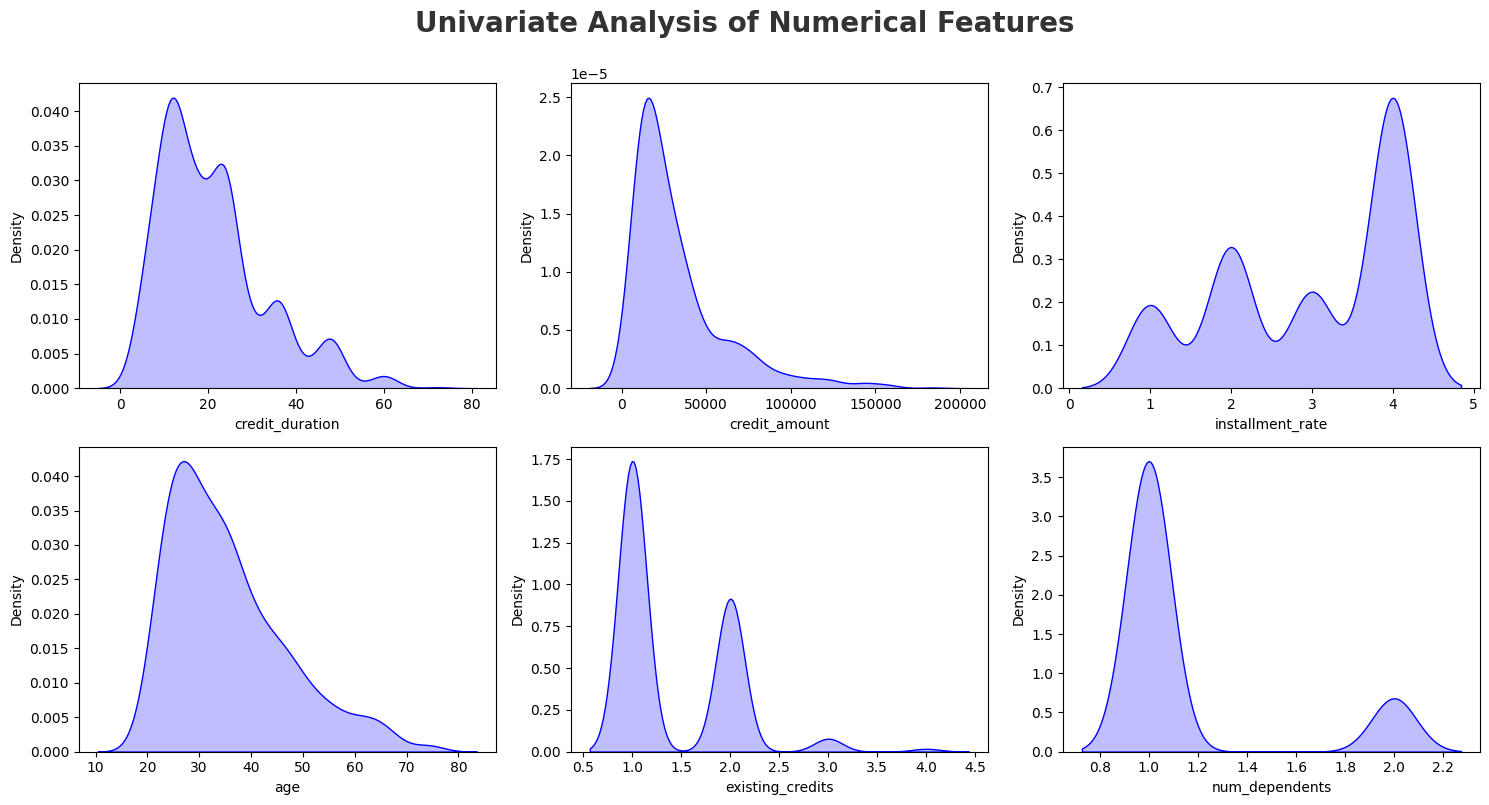

In [9]:
plt.figure(figsize=(15, 8))
plt.suptitle("Univariate Analysis of Numerical Features", fontsize=20, fontweight="bold", alpha=0.8, y=1.0)

for i in range(0, len(numeric_features)):
    plt.subplot(2, 3, i + 1)
    sns.kdeplot(x=df[numeric_features[i]], color="blue", fill=True)
    plt.xlabel(numeric_features[i])
    plt.tight_layout()

**Insights**
 - `credit_amount` is strongly right skewed, a few applicants ask for very large amounts.
 - `credit_duration` is right skewed as well and takes values in steps of six months.
 - `age` is right skewed, most applicants are between 25 and 45 years old.
 - `installment_rate`, `existing_credits` and `num_dependents` are discrete, they behave like categories.

### Categorical features

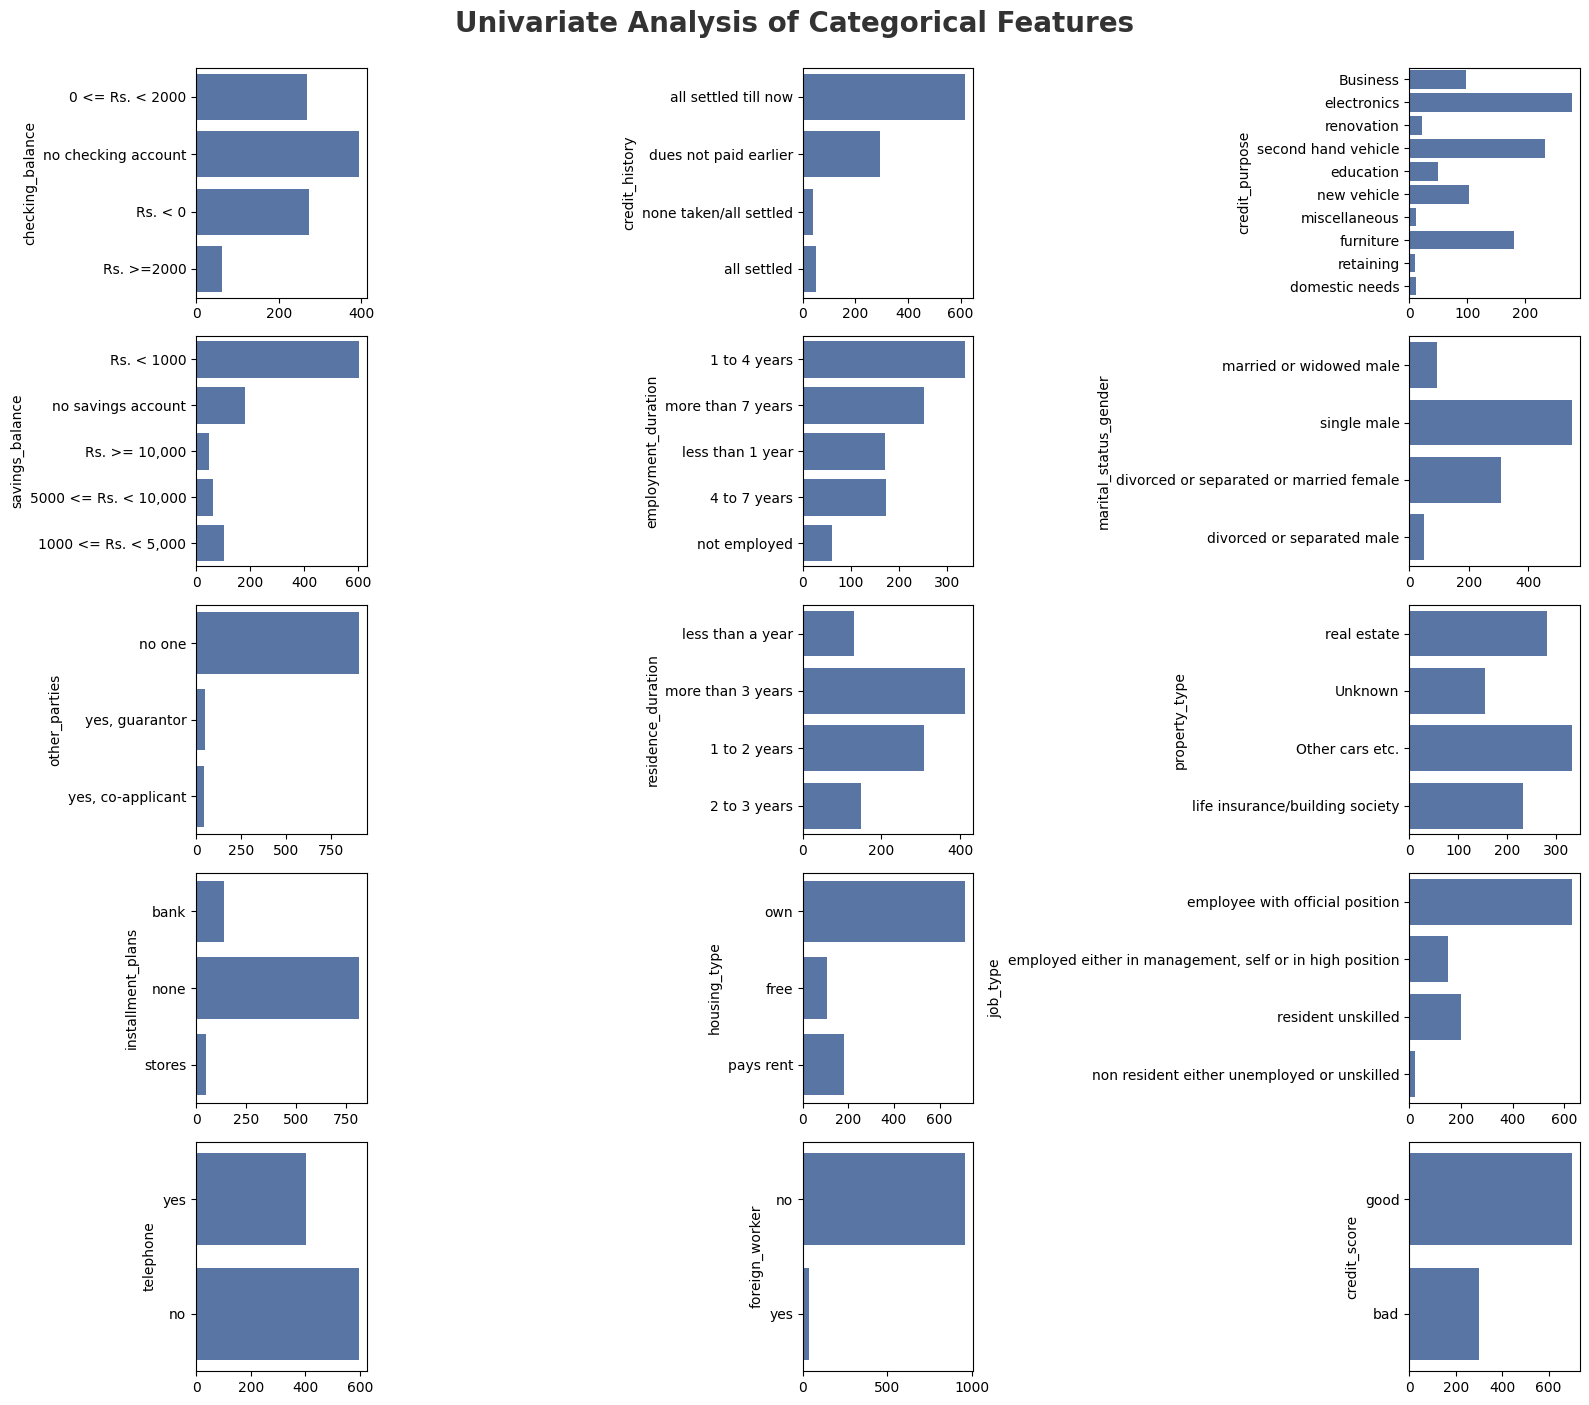

In [10]:
plt.figure(figsize=(16, 14))
plt.suptitle("Univariate Analysis of Categorical Features", fontsize=20, fontweight="bold", alpha=0.8, y=1.0)

for i in range(0, len(categorical_features)):
    plt.subplot(5, 3, i + 1)
    sns.countplot(y=df[categorical_features[i]], color="#4c72b0")
    plt.ylabel(categorical_features[i])
    plt.xlabel("")
    plt.tight_layout()

**Insights**
 - `credit_history` is dominated by applicants who paid everything back so far.
 - `foreign_worker`, `telephone` and `other_parties` have one category covering almost the whole dataset.
 - `credit_purpose` is the only categorical column with many levels, ten of them.

### Discrete and continuous features

In [11]:
discrete_features = [feature for feature in numeric_features if len(df[feature].unique()) <= 25]
continuous_features = [feature for feature in numeric_features if feature not in discrete_features]

print("We have {} discrete features : {}".format(len(discrete_features), discrete_features))
print("\nWe have {} continuous features : {}".format(len(continuous_features), continuous_features))

We have 3 discrete features : ['installment_rate', 'existing_credits', 'num_dependents']

We have 3 continuous features : ['credit_duration', 'credit_amount', 'age']


### Check the multicollinearity of the numerical features

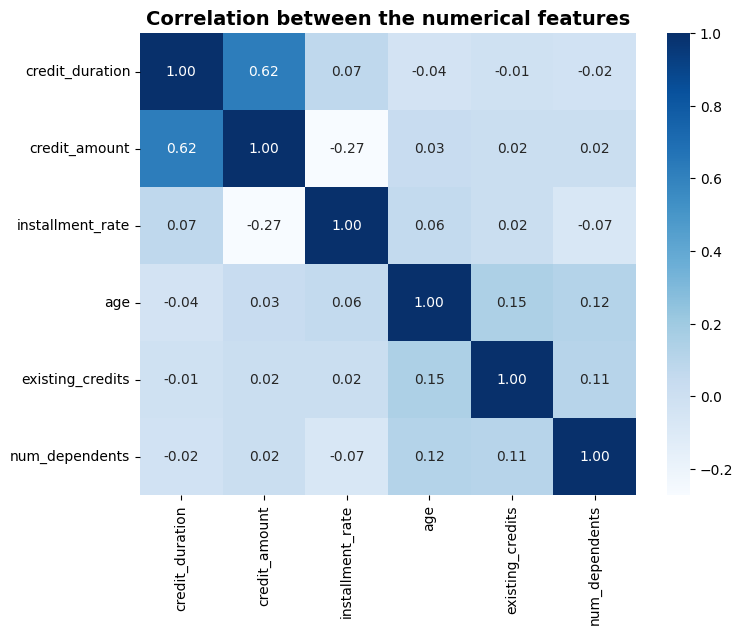

In [12]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation between the numerical features", fontsize=14, fontweight="bold")
plt.show()

**Insights**
 - `credit_amount` and `credit_duration` are the only pair with a noticeable correlation: the bigger
   the amount, the longer the repayment period. That relation is the reason why the feature
   engineering step later combines them into a single `monthly_installment` feature.
 - Apart from that pair there is no multicollinearity between the variables.

### Check the dependency of the categorical features on the target

* **A chi-squared test (also chi-square or χ2 test) is a statistical hypothesis test that is valid to
perform when the test statistic is chi-squared distributed under the null hypothesis, specifically
Pearson's chi-squared test.**

* **A chi-square statistic is one way to show a relationship between two categorical variables.**

* **Here we test the correlation of the categorical columns with the target column, `credit_score`.**

Null hypothesis ($H_0$): the feature is independent of the target column (no correlation)

Alternative hypothesis ($H_1$): the feature and the target column are not independent (correlated)

In [13]:
from scipy.stats import chi2_contingency

chi2_test = []
p_values = []
for feature in categorical_features:
    p_value = chi2_contingency(pd.crosstab(df["credit_score"], df[feature]))[1]
    p_values.append(round(p_value, 5))
    chi2_test.append("Reject Null Hypothesis" if p_value < 0.05 else "Fail to Reject Null Hypothesis")

result = pd.DataFrame({"Column": categorical_features, "p value": p_values, "Hypothesis Result": chi2_test})
result

,Column,p value,Hypothesis Result
0,checking_balance,0.00000,Reject Null Hypothesis
1,credit_history,0.00000,Reject Null Hypothesis
2,credit_purpose,0.00012,Reject Null Hypothesis
3,savings_balance,0.00000,Reject Null Hypothesis
4,employment_duration,0.00105,Reject Null Hypothesis
5,marital_status_gender,0.02224,Reject Null Hypothesis
6,other_parties,0.03606,Reject Null Hypothesis
7,residence_duration,0.86155,Fail to Reject Null Hypothesis
8,property_type,0.00003,Reject Null Hypothesis
9,installment_plans,0.00163,Reject Null Hypothesis


**Report**
* `residence_duration`, `job_type` and `telephone` fail to reject the null hypothesis, which means
  they do not correlate with the target column.
* `telephone` is the weakest of the three and carries no business meaning at all, so it is the
  column dropped by `drop_columns` in `config/schema.yaml`.
* `residence_duration` and `job_type` are kept, because they still describe the stability of the
  applicant and the tree based models can use them in combination with the other features.

## 4. Visualization

### 4.1 Visualize the target feature

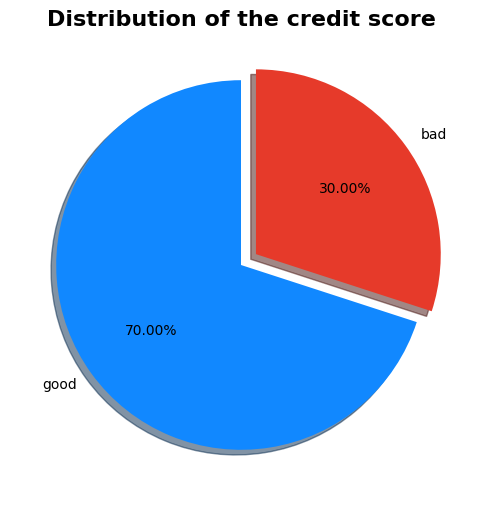

In [14]:
percentage = df.credit_score.value_counts(normalize=True) * 100
labels = list(percentage.index)

fig, ax = plt.subplots(figsize=(10, 6))
explode = (0, 0.1)
colors = ["#1188ff", "#e63a2a"]
ax.pie(percentage, labels=labels, startangle=90, autopct="%1.2f%%", explode=explode, shadow=True, colors=colors)
plt.title("Distribution of the credit score", fontsize=16, fontweight="bold")
plt.show()

* The chart shows that the target variable is imbalanced.

**What is imbalanced data?**

Imbalanced data is data where the target class has an uneven distribution of observations. Here the
`good` value has more than twice the count of the `bad` value, which means that a model predicting
"good" for everybody would already be right 70% of the time. This is the reason why the training
pipeline resamples the training set and why accuracy alone is not a sufficient metric.

### 4.2 Does the balance of the current account have an impact on the credit score?

In [15]:
df.groupby("checking_balance")["credit_score"].value_counts(normalize=True).to_frame() * 100

proportion
checking_balance    credit_score            
0 <= Rs. < 2000     good           60.966543
                    bad            39.033457
Rs. < 0             good           50.729927
                    bad            49.270073
Rs. >=2000          good           77.777778
                    bad            22.222222
no checking account good           88.324873
                    bad            11.675127

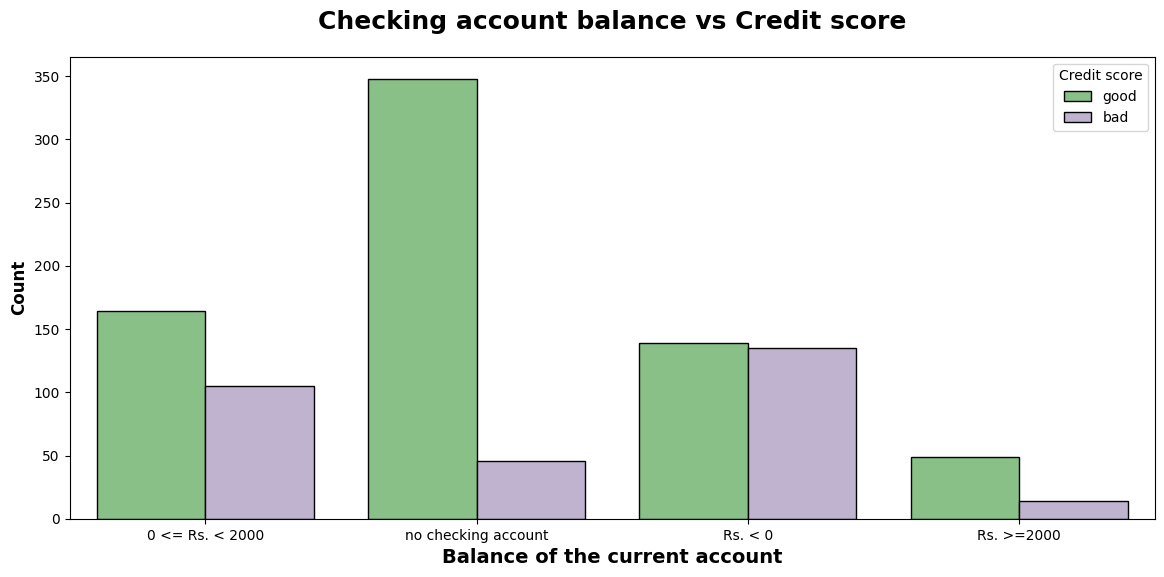

In [16]:
plt.subplots(figsize=(14, 6))
sns.countplot(x="checking_balance", hue="credit_score", data=df, ec="black", palette="Accent")
plt.title("Checking account balance vs Credit score", weight="bold", fontsize=18, pad=20)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.xlabel("Balance of the current account", weight="bold", fontsize=14)
plt.legend(title="Credit score", fancybox=True)
plt.show()

**Report**
* Applicants with **no checking account** are by far the safest group, only 12% of them were scored as bad.
* Applicants whose account is **overdrawn** (`Rs. < 0`) are the riskiest group, almost every second one was scored as bad.
* This is the single most informative column of the whole dataset.

### 4.3 Does the credit history have an impact on the credit score?

In [17]:
df.groupby("credit_history")["credit_score"].value_counts(normalize=True).to_frame() * 100

proportion
credit_history         credit_score            
all settled            bad            57.142857
                       good           42.857143
all settled till now   good           68.122977
                       bad            31.877023
dues not paid earlier  good           82.935154
                       bad            17.064846
none taken/all settled bad            62.500000
                       good           37.500000

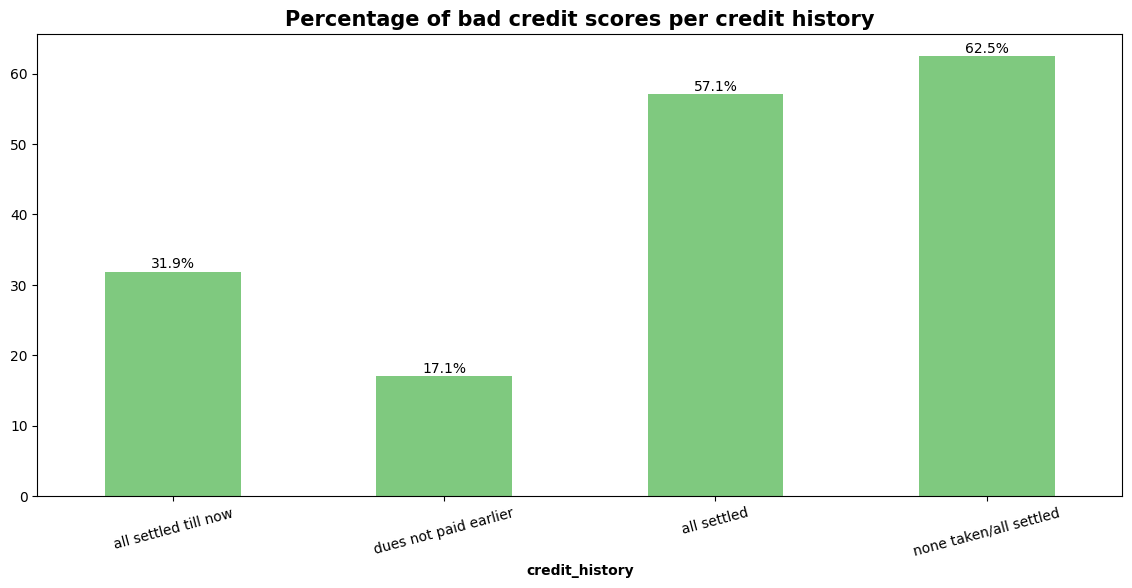

In [18]:
plt.figure(figsize=(14, 6))
order = df["credit_history"].value_counts().index
share = 100 * df[df["credit_score"] == "bad"]["credit_history"].value_counts() / df["credit_history"].value_counts()
share = share.loc[order]
share.plot(kind="bar", colormap="Accent")
plt.title("Percentage of bad credit scores per credit history", fontsize=15, fontweight="bold")
for n in range(share.shape[0]):
    plt.text(n, share.iloc[n] + 0.5, "{:0.1f}%".format(share.iloc[n]), ha="center")
plt.xlabel("credit_history", fontweight="bold")
plt.xticks(rotation=15)
plt.show()

**Report**
* Applicants who **never took a credit, or settled all of them**, are scored as bad in 60% of the cases,
  which looks surprising at first sight: the bank simply has no repayment evidence for them.
* Applicants with a history of **dues not paid earlier** are, on the contrary, among the safest ones,
  because that category groups the customers the bank knows well and still lends to.
* The column is clearly informative, whichever direction the effect goes.

### 4.4 Does the savings account balance have an impact on the credit score?

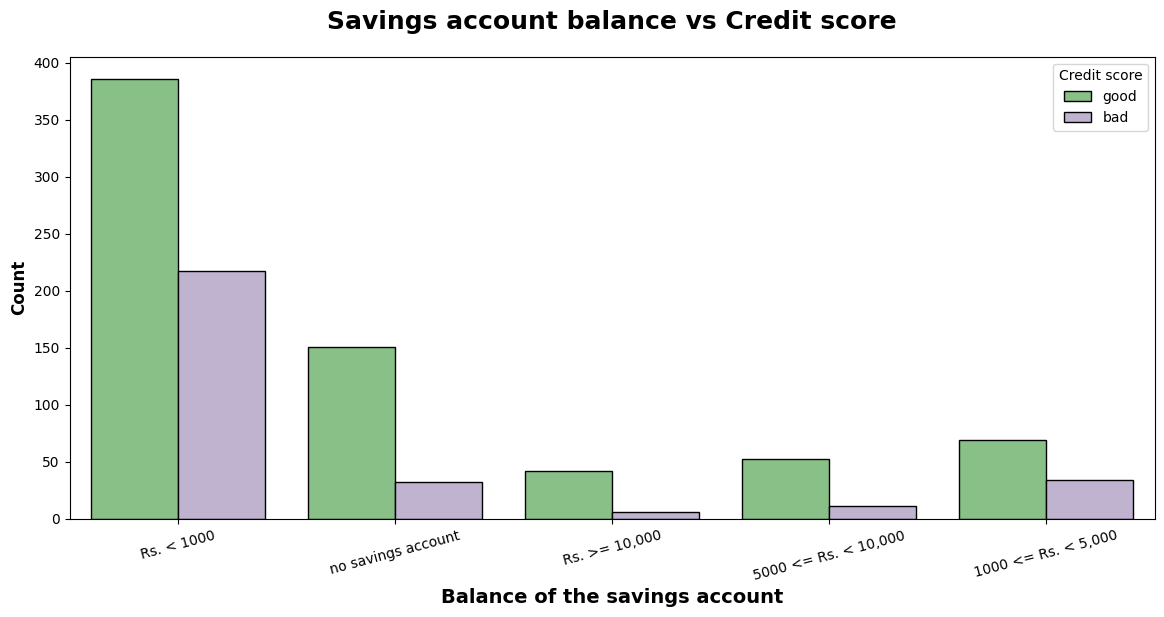

In [19]:
plt.subplots(figsize=(14, 6))
sns.countplot(x="savings_balance", hue="credit_score", data=df, ec="black", palette="Accent")
plt.title("Savings account balance vs Credit score", weight="bold", fontsize=18, pad=20)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.xlabel("Balance of the savings account", weight="bold", fontsize=14)
plt.xticks(rotation=15)
plt.legend(title="Credit score", fancybox=True)
plt.show()

**Insights**
 - The larger the savings, the smaller the share of bad credit scores.
 - Applicants with no savings account behave much better than applicants with a small one, for the
   same reason as the checking account: not having an account is not the same as having an empty one.

### 4.5 Does the employment duration have an impact on the credit score?

In [20]:
df.groupby("employment_duration")["credit_score"].value_counts(normalize=True).to_frame() * 100

proportion
employment_duration credit_score            
1 to 4 years        good           69.321534
                    bad            30.678466
4 to 7 years        good           77.586207
                    bad            22.413793
less than 1 year    good           59.302326
                    bad            40.697674
more than 7 years   good           74.703557
                    bad            25.296443
not employed        good           62.903226
                    bad            37.096774

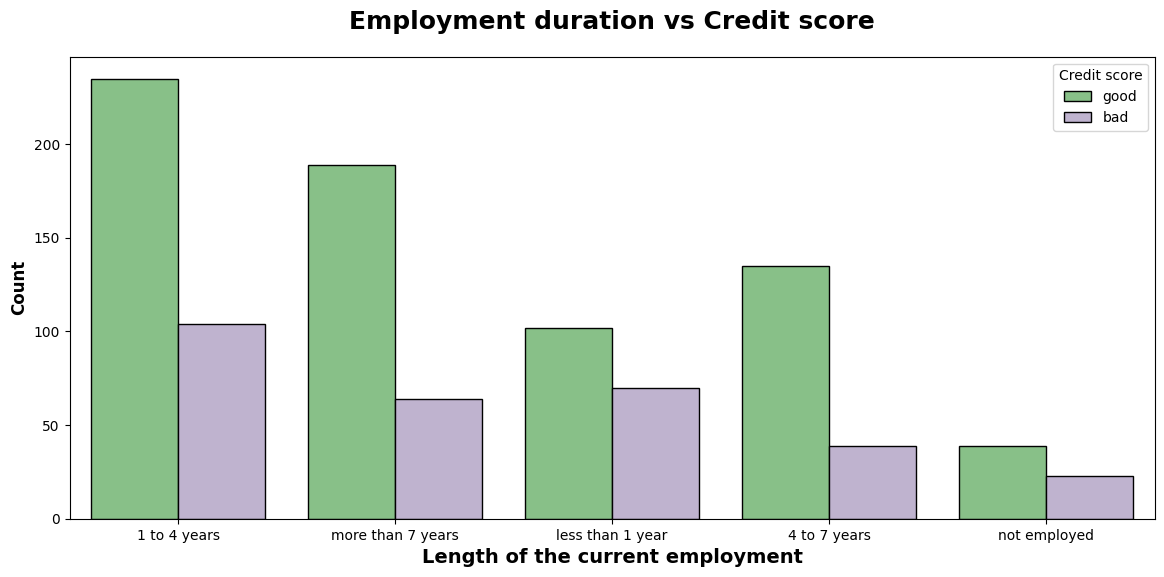

In [21]:
plt.subplots(figsize=(14, 6))
sns.countplot(x="employment_duration", hue="credit_score", data=df, ec="black", palette="Accent")
plt.title("Employment duration vs Credit score", weight="bold", fontsize=18, pad=20)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.xlabel("Length of the current employment", weight="bold", fontsize=14)
plt.legend(title="Credit score", fancybox=True)
plt.show()

**Report**
* Applicants employed for **more than 7 years** have the smallest share of bad scores.
* Applicants who are **not employed** or employed for **less than a year** are the riskiest.
* Job stability matters, exactly as a credit officer would expect.

### 4.6 Does the purpose of the credit have an impact on the credit score?

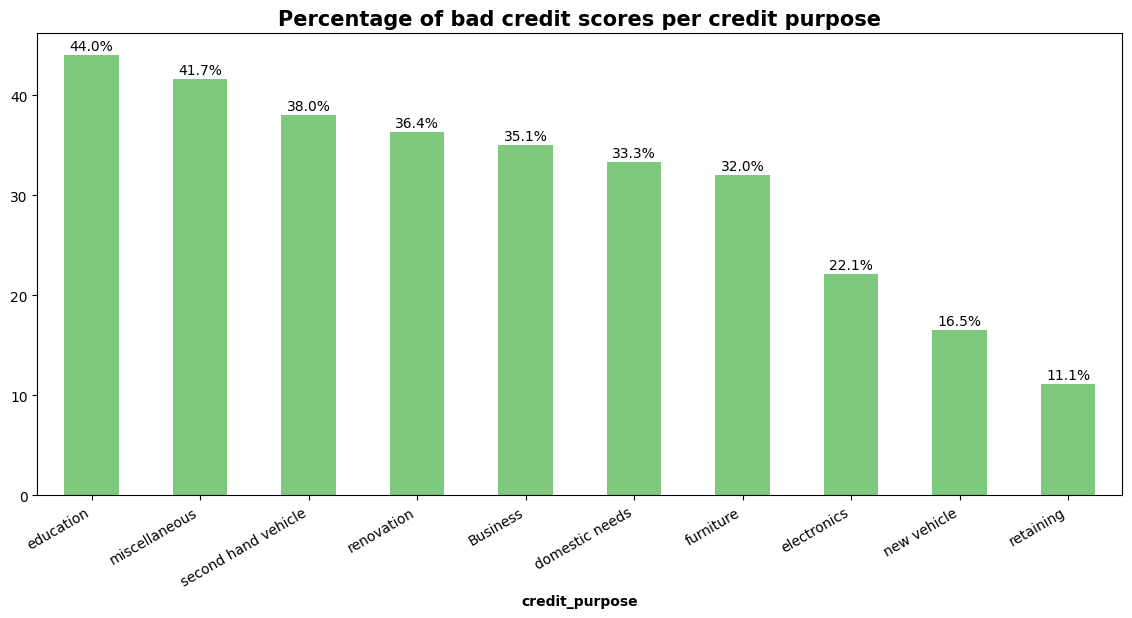

In [22]:
plt.figure(figsize=(14, 6))
share = 100 * df[df["credit_score"] == "bad"]["credit_purpose"].value_counts() / df["credit_purpose"].value_counts()
share = share.sort_values(ascending=False)
share.plot(kind="bar", colormap="Accent")
plt.title("Percentage of bad credit scores per credit purpose", fontsize=15, fontweight="bold")
for n in range(share.shape[0]):
    plt.text(n, share.iloc[n] + 0.5, "{:0.1f}%".format(share.iloc[n]), ha="center")
plt.xlabel("credit_purpose", fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.show()

**Report**
* Credits taken for **education** and for **new vehicles** show the highest share of bad scores.
* Credits taken for **retaining** and for **second hand vehicles** are the safest ones.
* The differences are visible but moderate, which matches the chi-squared p value of 0.0001.

### 4.7 Do the numerical features have an impact on the credit score?

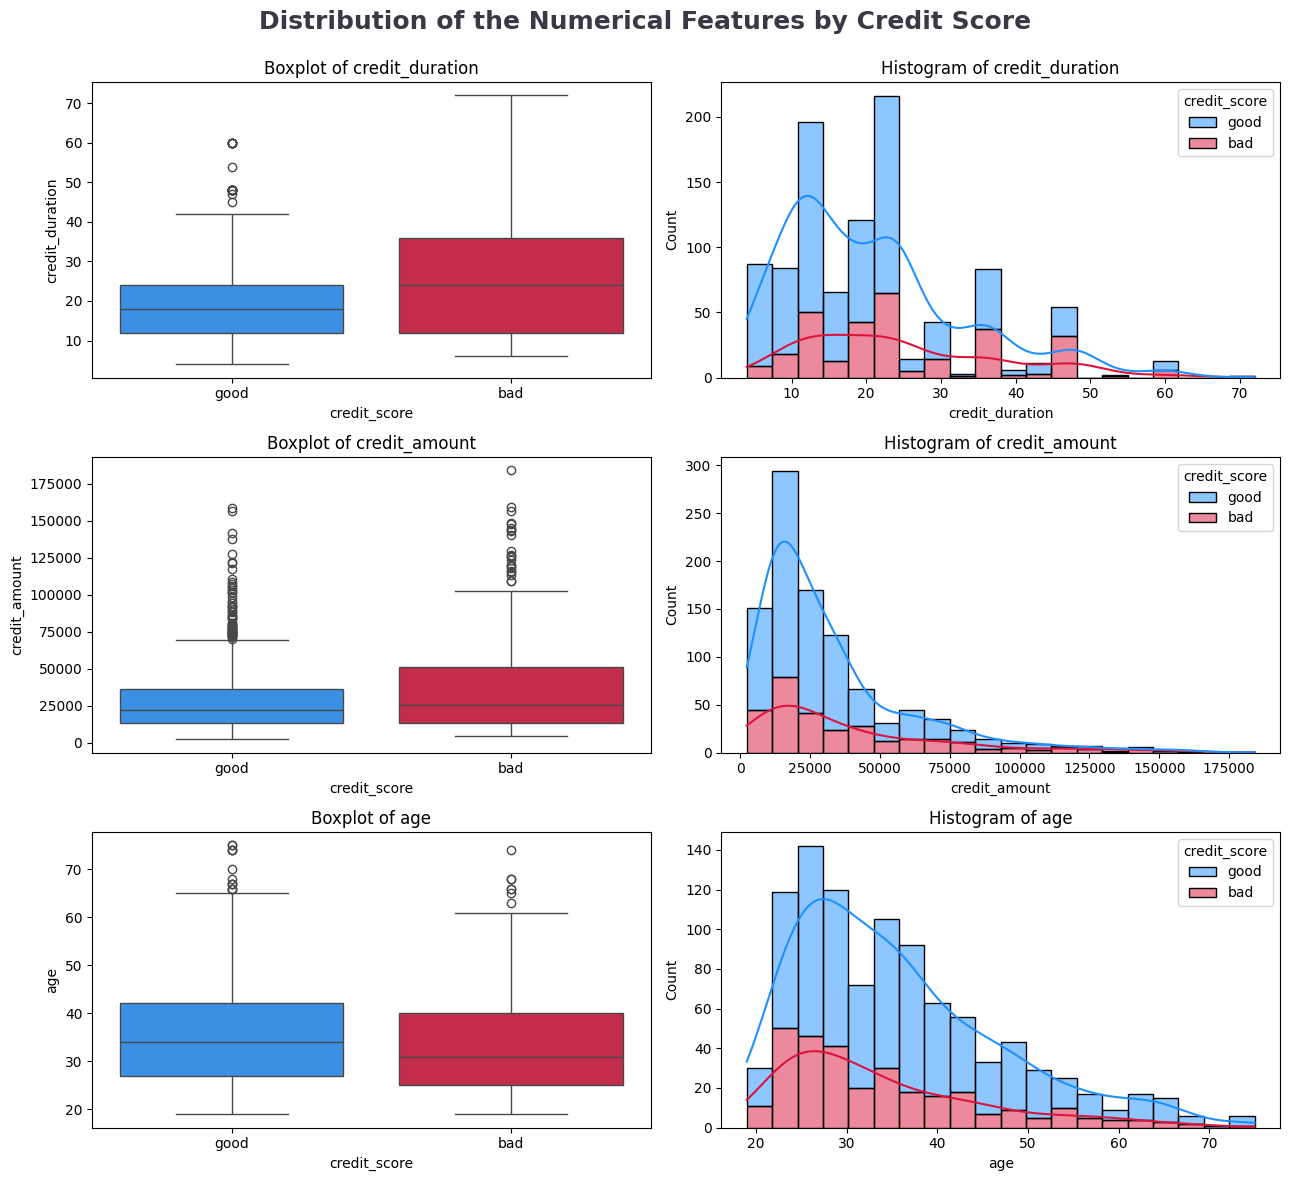

In [23]:
clr1 = ["#1E90FF", "#DC143C"]
fig, ax = plt.subplots(3, 2, figsize=(13, 12))
fig.suptitle("Distribution of the Numerical Features by Credit Score", color="#3C3744",
             fontsize=18, fontweight="bold", ha="center")
for i, col in enumerate(continuous_features):
    sns.boxplot(data=df, x="credit_score", y=col, palette=clr1, ax=ax[i, 0])
    ax[i, 0].set_title(f"Boxplot of {col}", fontsize=12)
    sns.histplot(data=df, x=col, hue="credit_score", bins=20, kde=True,
                 multiple="stack", palette=clr1, ax=ax[i, 1])
    ax[i, 1].set_title(f"Histogram of {col}", fontsize=12)
fig.tight_layout()
fig.subplots_adjust(top=0.92)

In [24]:
df.groupby("credit_score")[continuous_features].median()

,credit_duration,credit_amount,age
credit_score,,,
bad,24.0,25625.0,31.0
good,18.0,22320.0,34.0


**Report**
* Applicants scored as bad ask for **larger amounts** over a **longer period**, the median duration
  is 24 months against 18 for the good ones.
* Applicants scored as bad are **slightly younger**.
* All three columns contain outliers above the upper whisker, which is why the pipeline applies a
  Yeo-Johnson power transform to `credit_amount` and to `age`.

### 4.8 Credit amount and duration together

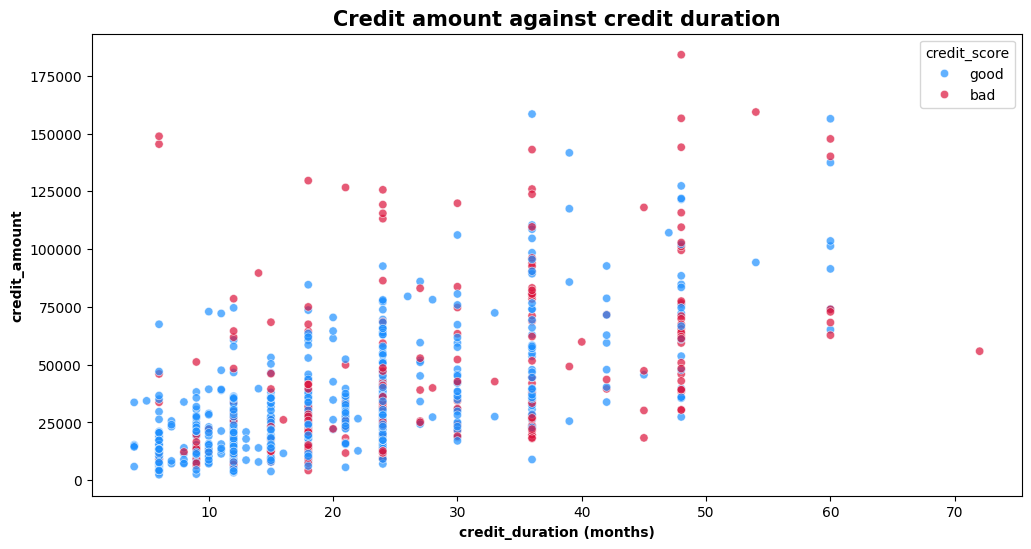

In [25]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x="credit_duration", y="credit_amount", hue="credit_score", palette=clr1, alpha=0.7)
plt.title("Credit amount against credit duration", fontsize=15, fontweight="bold")
plt.xlabel("credit_duration (months)", fontweight="bold")
plt.ylabel("credit_amount", fontweight="bold")
plt.show()

**Insights**
 - The two columns grow together, and the applications sitting **above** the cloud, meaning a large
   amount over a short period, are much more often scored as bad.
 - That ratio, amount divided by duration, is not available to the model as such: it is created in
   the feature engineering stage under the name `monthly_installment`.

## Final report

* There is no identifier column to drop, every column describes the application itself.
* `telephone` does not correlate with the target and has no business meaning, so it is dropped.
* `credit_amount`, `credit_duration` and `age` are right skewed and contain outliers, which should be
  handled by a power transform.
* `checking_balance`, `credit_history`, `savings_balance` and `employment_duration` are ordinal
  categories: their levels have a natural order, which should be preserved by the encoder.
* `credit_amount` and `credit_duration` are correlated and their ratio carries additional information,
  so a `monthly_installment` feature is created.
* The target column `credit_score` is imbalanced, 70/30, and has to be handled before model building.

In [26]:
########################-------------Feature Engineering and Model Training in the next notebook------------###########################